# EDA & Phân Tích Thống Kê Tổng Quan
## Dự án: Khám Phá Dữ Liệu Sức Khỏe Tâm Thần
**Người thực hiện:** Đỗ Anh Khoa  
**Nhiệm vụ:** EDA & Phân tích thống kê tổng quan  
**Dataset:** Kaggle - Playground Series S4E11 (Exploring Mental Health Data)


In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11


# 1. Tổng quan dataset

In [18]:
train = pd.read_csv('data/raw/train.csv')
test = pd.read_csv('data/raw/test.csv')

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print()
print("5 dòng đầu tiên của train set:")
train.head()

Train shape: (140700, 20)
Test shape: (93800, 19)

5 dòng đầu tiên của train set:


,id,Name,Gender,Age,City,Working Professional or Student,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,0,Aaradhya,Female,49.0,Ludhiana,Working Professional,Chef,NaN,5.0,NaN,NaN,2.0,More than 8 hours,Healthy,BHM,No,1.0,2.0,No,0
1,1,Vivan,Male,26.0,Varanasi,Working Professional,Teacher,NaN,4.0,NaN,NaN,3.0,Less than 5 hours,Unhealthy,LLB,Yes,7.0,3.0,No,1
2,2,Yuvraj,Male,33.0,Visakhapatnam,Student,NaN,5.0,NaN,8.97,2.0,NaN,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
3,3,Yuvraj,Male,22.0,Mumbai,Working Professional,Teacher,NaN,5.0,NaN,NaN,1.0,Less than 5 hours,Moderate,BBA,Yes,10.0,1.0,Yes,1
4,4,Rhea,Female,30.0,Kanpur,Working Professional,Business Analyst,NaN,1.0,NaN,NaN,1.0,5-6 hours,Unhealthy,BBA,Yes,9.0,4.0,Yes,0


**Mỗi dòng trong dataset đại diện cho:**
- **1 người** (cá nhân)
- **Các thuộc tính (Features)**: Tuổi, Giới tính, Số giờ làm/học, Áp lực công việc/học tập, Thói quen ăn uống, Thời gian ngủ, Lịch sử tâm thần gia đình, v.v.
- **Nhãn (Label)**: `Depression` 
  - `0` = Không trầm cảm
  - `1` = Có trầm cảm

**Mục tiêu:** Dự đoán xác suất người đó bị trầm cảm dựa trên các đặc điểm cá nhân.

### Kiểu dữ liệu các cột

In [ ]:

print("Kiểu dữ liệu từng cột:")
print(train.dtypes)
print()

# Phân loại cột theo kiểu
num_cols = train.select_dtypes(include='number').columns.tolist()
cat_cols = train.select_dtypes(include='object').columns.tolist()
num_cols = [c for c in num_cols if c not in ['id', 'Depression']]
cat_cols = [c for c in cat_cols if c != 'Name']

print(f"Biến số (Numerical): {num_cols}")
print(f"Biến phân loại (Categorical): {cat_cols}")


Kiểu dữ liệu từng cột:
id                                         int64
Name                                      object
Gender                                    object
Age                                      float64
City                                      object
Working Professional or Student           object
Profession                                object
Academic Pressure                        float64
Work Pressure                            float64
CGPA                                     float64
Study Satisfaction                       float64
Job Satisfaction                         float64
Sleep Duration                            object
Dietary Habits                            object
Degree                                    object
Have you ever had suicidal thoughts ?     object
Work/Study Hours                         float64
Financial Stress                         float64
Family History of Mental Illness          object
Depression                                 int

### Thống kê mô tả

In [ ]:

train.describe()

,id,Age,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Work/Study Hours,Financial Stress,Depression
count,140700.000000,140700.000000,27897.000000,112782.000000,27898.000000,27897.000000,112790.000000,140700.000000,140696.000000,140700.000000
mean,70349.500000,40.388621,3.142273,2.998998,7.658636,2.944940,2.974404,6.252679,2.988983,0.181713
std,40616.735775,12.384099,1.380457,1.405771,1.464466,1.360197,1.416078,3.853615,1.413633,0.385609
min,0.000000,18.000000,1.000000,1.000000,5.030000,1.000000,1.000000,0.000000,1.000000,0.000000
25%,35174.750000,29.000000,2.000000,2.000000,6.290000,2.000000,2.000000,3.000000,2.000000,0.000000
50%,70349.500000,42.000000,3.000000,3.000000,7.770000,3.000000,3.000000,6.000000,3.000000,0.000000
75%,105524.250000,51.000000,4.000000,4.000000,8.920000,4.000000,4.000000,10.000000,4.000000,0.000000
max,140699.000000,60.000000,5.000000,5.000000,10.000000,5.000000,5.000000,12.000000,5.000000,1.000000


### Missing values

In [ ]:

missing       = train.isnull().sum()
missing_pct   = (missing / len(train) * 100).round(2)
missing_df    = pd.DataFrame({'Số lượng missing': missing, 'Tỉ lệ (%)': missing_pct})
missing_df    = missing_df[missing_df['Số lượng missing'] > 0].sort_values('Số lượng missing', ascending=False)

print("Các cột có missing values trong tập train:")
print(missing_df)



Các cột có missing values trong tập train:
                    Số lượng missing  Tỉ lệ (%)
Academic Pressure             112803      80.17
Study Satisfaction            112803      80.17
CGPA                          112802      80.17
Profession                     36630      26.03
Work Pressure                  27918      19.84
Job Satisfaction               27910      19.84
Dietary Habits                     4       0.00
Financial Stress                   4       0.00
Degree                             2       0.00


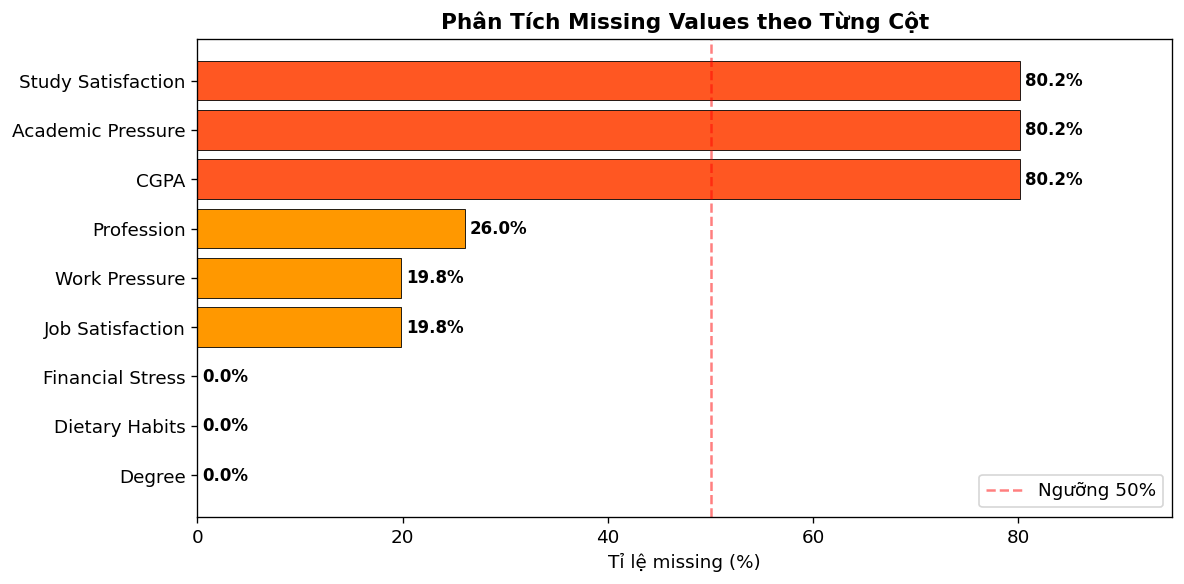

In [12]:
# Biểu đồ Missing Values
missing_plot = (train.isnull().sum() / len(train) * 100)
missing_plot = missing_plot[missing_plot > 0].sort_values(ascending=True)

colors_bar = ['#FF5722' if x > 50 else '#FF9800' if x > 10 else '#FFC107' for x in missing_plot.values]
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(missing_plot.index, missing_plot.values, color=colors_bar, edgecolor='black', linewidth=0.5)
for bar, val in zip(bars, missing_plot.values):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', fontsize=10, fontweight='bold')
ax.set_xlabel('Tỉ lệ missing (%)')
ax.set_title('Phân Tích Missing Values theo Từng Cột', fontsize=13, fontweight='bold')
ax.set_xlim(0, 95)
ax.axvline(x=50, color='red', linestyle='--', alpha=0.5, label='Ngưỡng 50%')
ax.legend()
plt.tight_layout()
plt.show()


**1. Hiện tượng "Missing Not At Random" (Thiếu có chủ đích)**

Sự thiếu hụt này mang tính cấu trúc. Tập dữ liệu này rõ ràng được gộp từ hai nhóm đối tượng chính: **Người đi làm** và **Học sinh/Sinh viên**.

- Nếu một người là người đi làm (chiếm khoảng ~80% dataset), họ sẽ không có điểm CGPA hay Academic Pressure, dẫn đến các cột này bị bỏ trống.

- Ngược lại, nếu một người là sinh viên (chiếm khoảng ~20% dataset), họ sẽ không có Work Pressure hay Job Satisfaction.

- Việc Profession có tỉ lệ thiếu cao hơn một chút (26.03%) so với các cột công việc khác có thể do một nhóm đối tượng là người thất nghiệp, nội trợ, hoặc đây chính là một trong những "data artifacts" (nhiễu dữ liệu) được tạo ra trong quá trình sinh dữ liệu tổng hợp (synthetic data) như mô tả của cuộc thi.

**2. Nhóm thiếu hụt ngẫu nhiên tỉ lệ cực thấp**

Các cột Dietary Habits (4 dòng), Financial Stress (4 dòng), và Degree (2 dòng) có tỉ lệ missing gần như bằng 0.00%.

- Nhận xét: Đây là những lỗi rớt dữ liệu ngẫu nhiên thông thường (Missing Completely At Random - MCAR) trong quá trình thu thập hoặc sinh dữ liệu. Nó không ảnh hưởng đến cấu trúc tổng thể.

### Kiểm tra Trùng lặp

In [15]:
dup_rows = train.duplicated()
percent = dup_rows.sum() / train.shape[0] * 100
print(f"Số nhóm trùng lặp: {dup_rows.sum()} ({percent:.2f}%)")

duplicated_rows_all = train[train.duplicated(keep=False)]
duplicated_rows_all

Số nhóm trùng lặp: 0 (0.00%)


,id,Name,Gender,Age,City,Working Professional or Student,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression


# 2. Khám phá dữ liệu (EDA)


Phân phối nhãn Depression:
  Không trầm cảm (0): 115,133 mẫu (81.8%)
  Trầm cảm       (1): 25,567 mẫu (18.2%)
  Tỉ lệ mất cân bằng: 4.5:1

⚠️  Nhận xét: Dataset bị mất cân bằng lớp khá nặng (4.5:1)
   → Cần xử lý class imbalance ở bước tiếp theo (SMOTE, class_weight...)


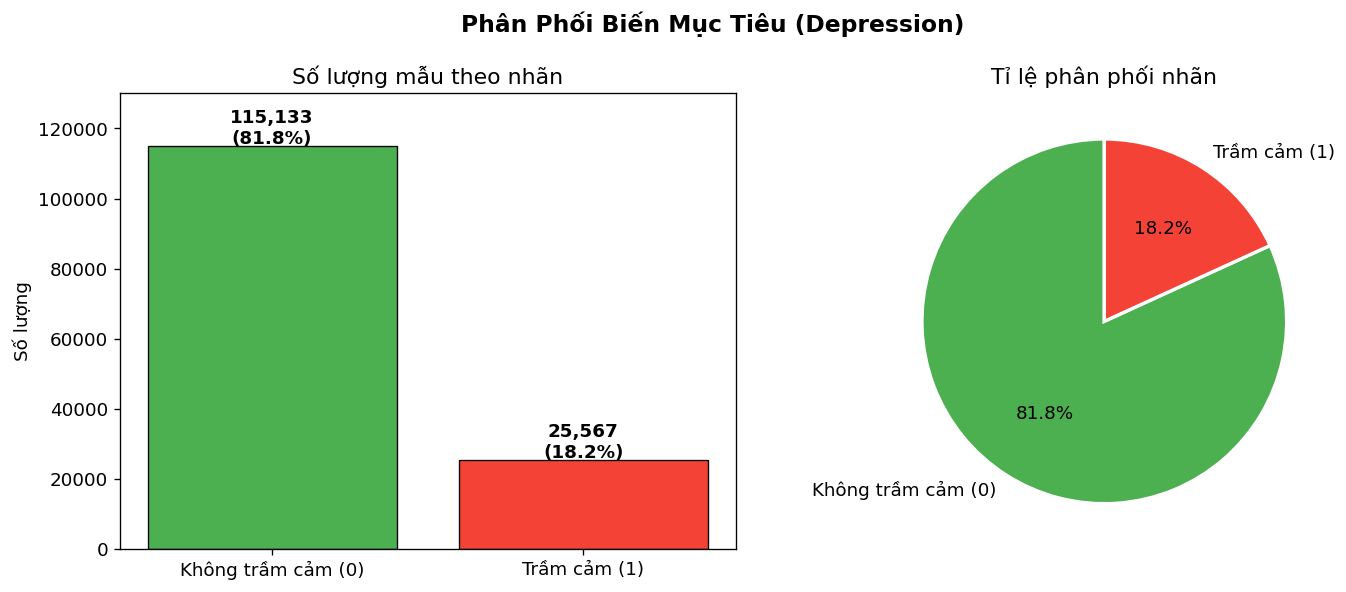

In [7]:

# 5. PHÂN TÍCH PHÂN PHỐI BIẾN MỤC TIÊU (CLASS IMBALANCE)

counts = train['Depression'].value_counts()
ratio  = round(counts[0] / counts[1], 2)

print("Phân phối nhãn Depression:")
print(f"  Không trầm cảm (0): {counts[0]:,} mẫu ({counts[0]/len(train)*100:.1f}%)")
print(f"  Trầm cảm       (1): {counts[1]:,} mẫu ({counts[1]/len(train)*100:.1f}%)")
print(f"  Tỉ lệ mất cân bằng: {ratio}:1")
print()
print("⚠️  Nhận xét: Dataset bị mất cân bằng lớp khá nặng (4.5:1)")
print("   → Cần xử lý class imbalance ở bước tiếp theo (SMOTE, class_weight...)")

# Biểu đồ
labels  = ['Không trầm cảm (0)', 'Trầm cảm (1)']
colors  = ['#4CAF50', '#F44336']
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Phân Phối Biến Mục Tiêu (Depression)', fontsize=14, fontweight='bold')

axes[0].bar(labels, counts.values, color=colors, edgecolor='black', linewidth=0.8)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 500, f'{v:,}\n({v/len(train)*100:.1f}%)', ha='center', fontsize=11, fontweight='bold')
axes[0].set_title('Số lượng mẫu theo nhãn')
axes[0].set_ylabel('Số lượng')
axes[0].set_ylim(0, 130000)

axes[1].pie(counts.values, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Tỉ lệ phân phối nhãn')

plt.tight_layout()
plt.show()


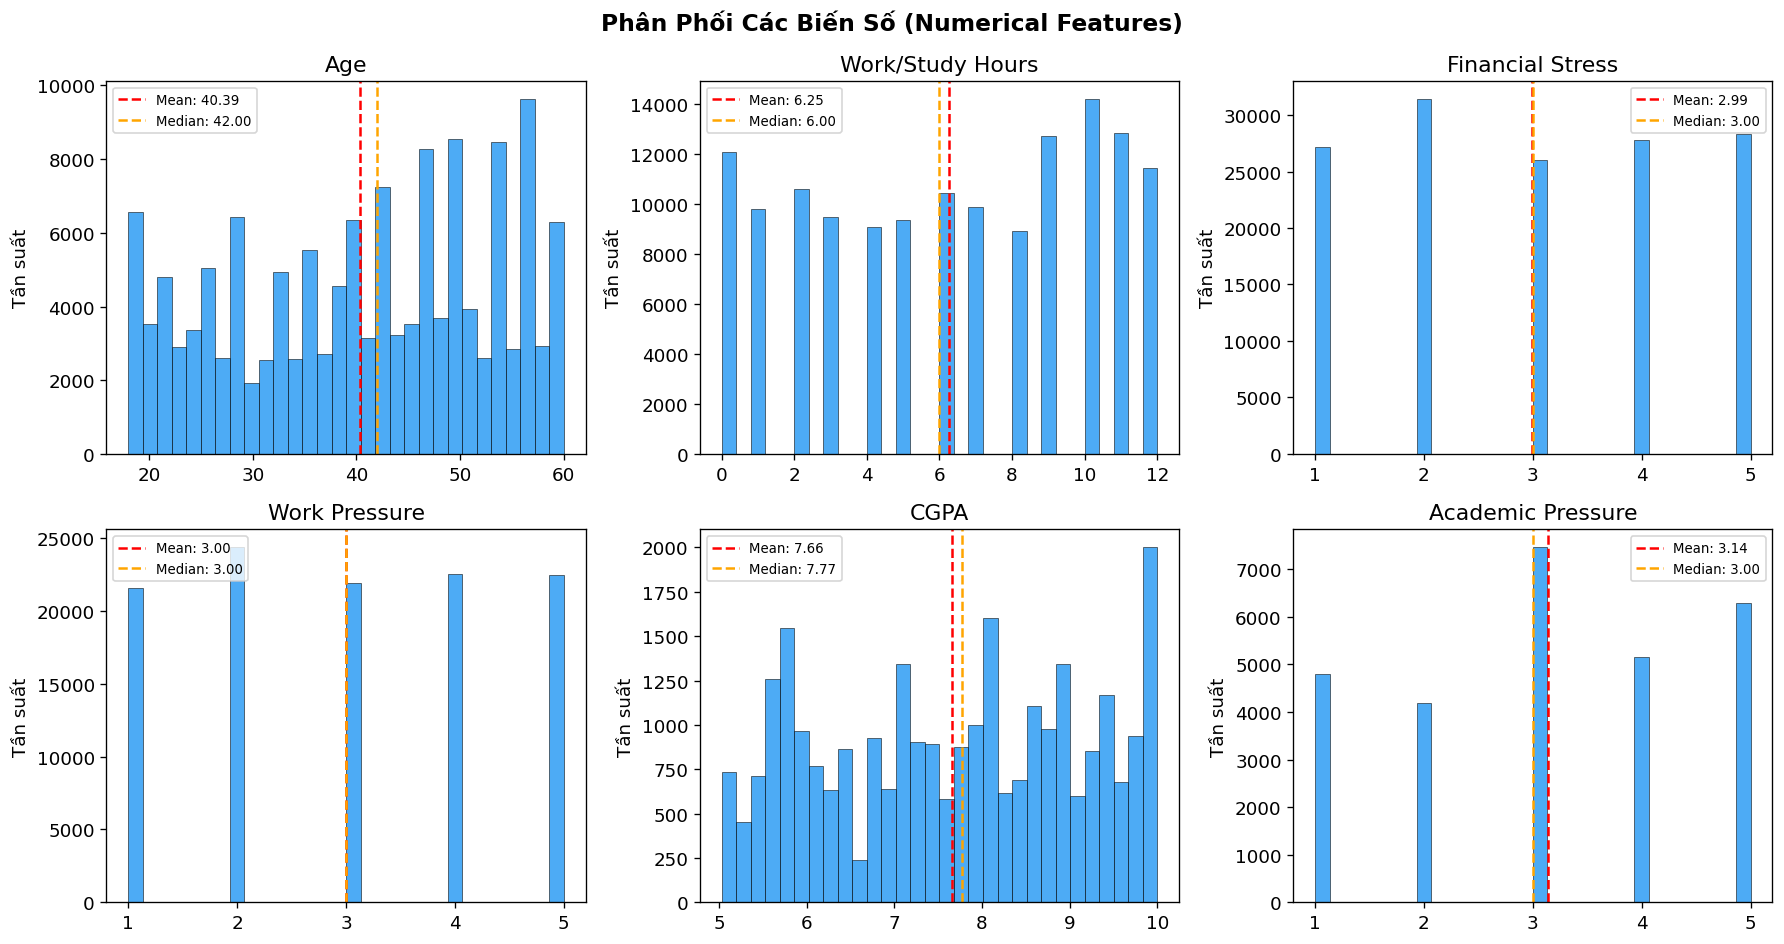

📌 Nhận xét:
- Age phân phối tương đối đồng đều (18–60 tuổi), trung bình ~40
- Work/Study Hours: tập trung 3–10 giờ/ngày
- Financial Stress: thang điểm 1–5, phân phối gần đều
- CGPA, Academic Pressure: chỉ có ở nhóm sinh viên (~20% dataset)


In [8]:

# 6. PHÂN PHỐI CÁC BIẾN SỐ (NUMERICAL FEATURES)

num_plot = ['Age', 'Work/Study Hours', 'Financial Stress', 'Work Pressure', 'CGPA', 'Academic Pressure']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Phân Phối Các Biến Số (Numerical Features)', fontsize=14, fontweight='bold')

for i, col in enumerate(num_plot):
    ax   = axes[i//3][i%3]
    data = train[col].dropna()
    ax.hist(data, bins=30, color='#2196F3', edgecolor='black', linewidth=0.4, alpha=0.8)
    ax.axvline(data.mean(),   color='red',    linestyle='--', label=f'Mean: {data.mean():.2f}')
    ax.axvline(data.median(), color='orange', linestyle='--', label=f'Median: {data.median():.2f}')
    ax.set_title(col)
    ax.set_ylabel('Tần suất')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print("📌 Nhận xét:")
print("- Age phân phối tương đối đồng đều (18–60 tuổi), trung bình ~40")
print("- Work/Study Hours: tập trung 3–10 giờ/ngày")
print("- Financial Stress: thang điểm 1–5, phân phối gần đều")
print("- CGPA, Academic Pressure: chỉ có ở nhóm sinh viên (~20% dataset)")


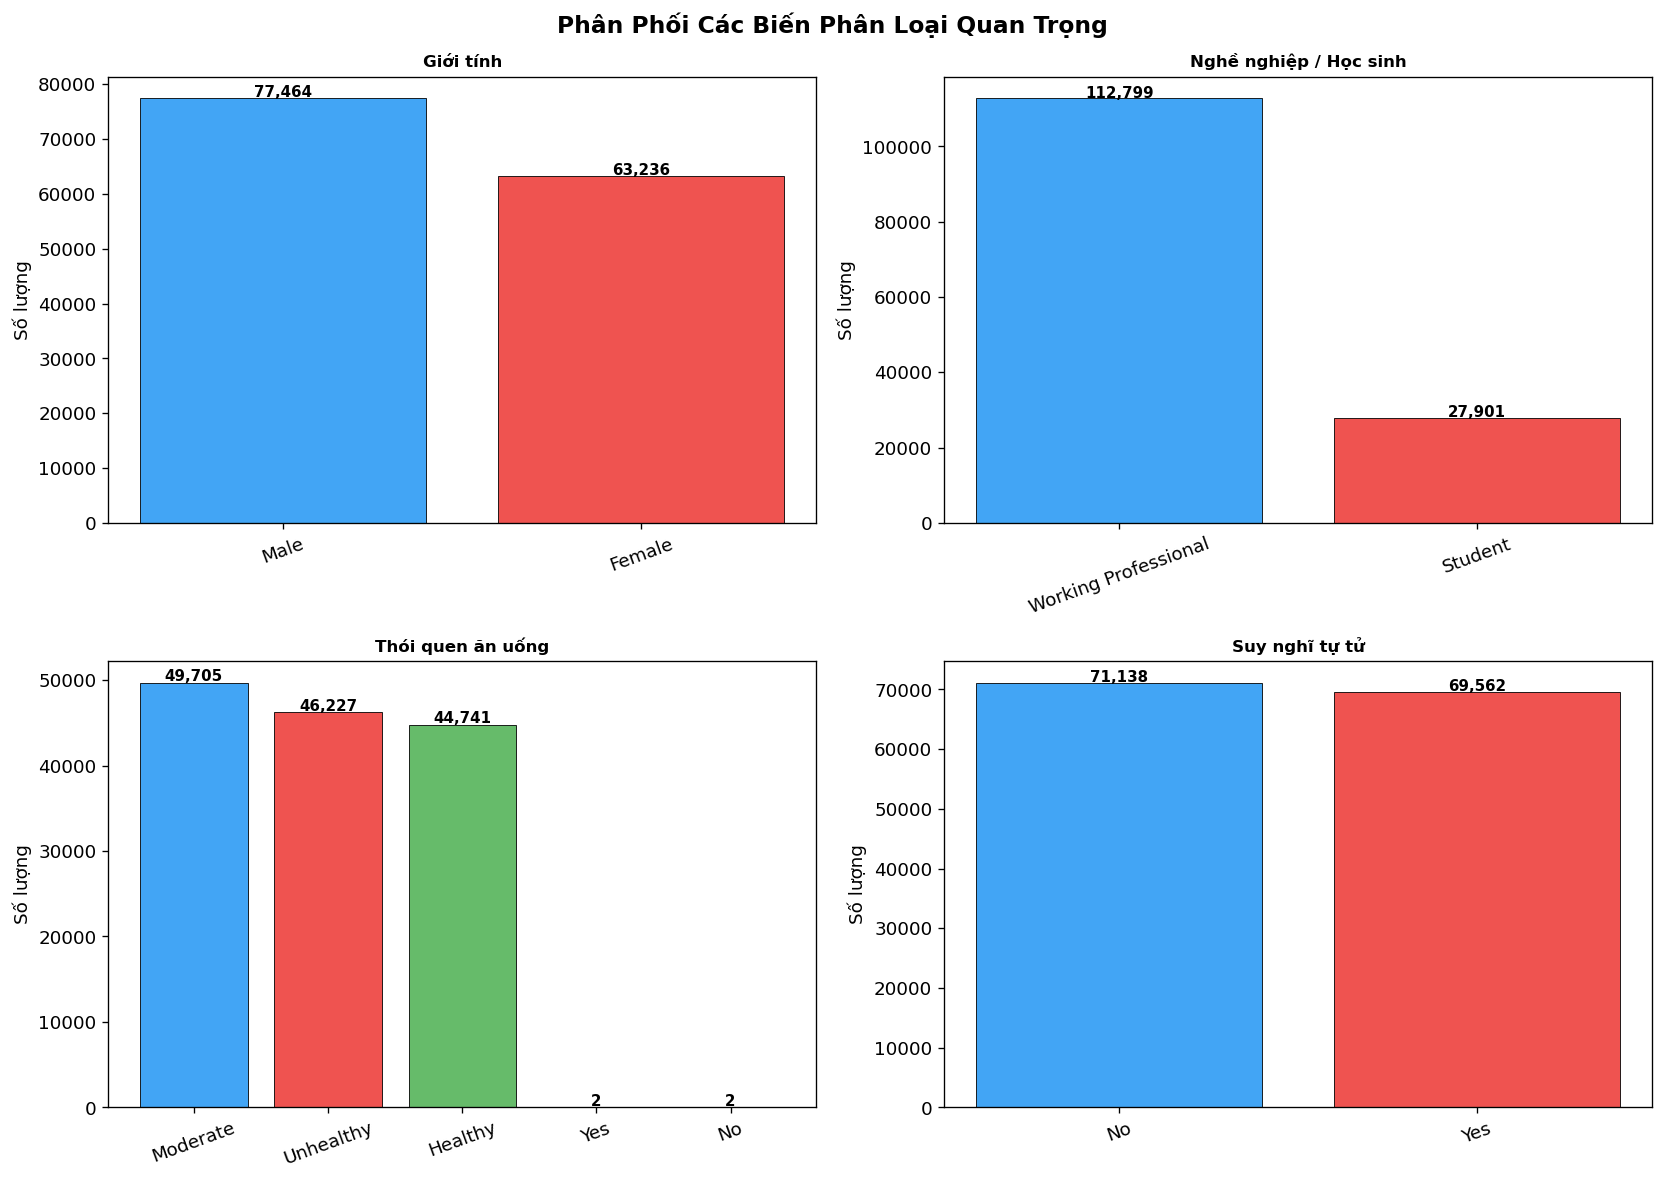

📌 Nhận xét:
- Giới tính: Nam chiếm ~55%, Nữ ~45% — tương đối cân bằng
- 80% là Working Professional, 20% là Student
- Dietary Habits phân phối khá đều (Moderate/Unhealthy/Healthy)
- Gần 50% từng có suy nghĩ tự tử — feature rất quan trọng cho prediction


In [9]:

# 7. PHÂN PHỐI CÁC BIẾN PHÂN LOẠI (CATEGORICAL FEATURES)

cat_plot = [
    ('Gender', 'Giới tính'),
    ('Working Professional or Student', 'Nghề nghiệp / Học sinh'),
    ('Dietary Habits', 'Thói quen ăn uống'),
    ('Have you ever had suicidal thoughts ?', 'Suy nghĩ tự tử'),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Phân Phối Các Biến Phân Loại Quan Trọng', fontsize=14, fontweight='bold')
colors_cat = ['#42A5F5', '#EF5350', '#66BB6A', '#FFA726', '#AB47BC']

for (col, title), ax in zip(cat_plot, axes.flatten()):
    vc = train[col].value_counts().head(5)
    ax.bar(vc.index, vc.values, color=colors_cat[:len(vc)], edgecolor='black', linewidth=0.5)
    for j, v in enumerate(vc.values):
        ax.text(j, v + 200, f'{v:,}', ha='center', fontsize=9, fontweight='bold')
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_ylabel('Số lượng')
    ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

print("📌 Nhận xét:")
print("- Giới tính: Nam chiếm ~55%, Nữ ~45% — tương đối cân bằng")
print("- 80% là Working Professional, 20% là Student")
print("- Dietary Habits phân phối khá đều (Moderate/Unhealthy/Healthy)")
print("- Gần 50% từng có suy nghĩ tự tử — feature rất quan trọng cho prediction")


Phát hiện Outliers bằng phương pháp IQR:
  Age: Q1=29.0, Q3=51.0, IQR=22.0 | Outliers: 0 (0.00%)
  Work/Study Hours: Q1=3.0, Q3=10.0, IQR=7.0 | Outliers: 0 (0.00%)
  Financial Stress: Q1=2.0, Q3=4.0, IQR=2.0 | Outliers: 0 (0.00%)


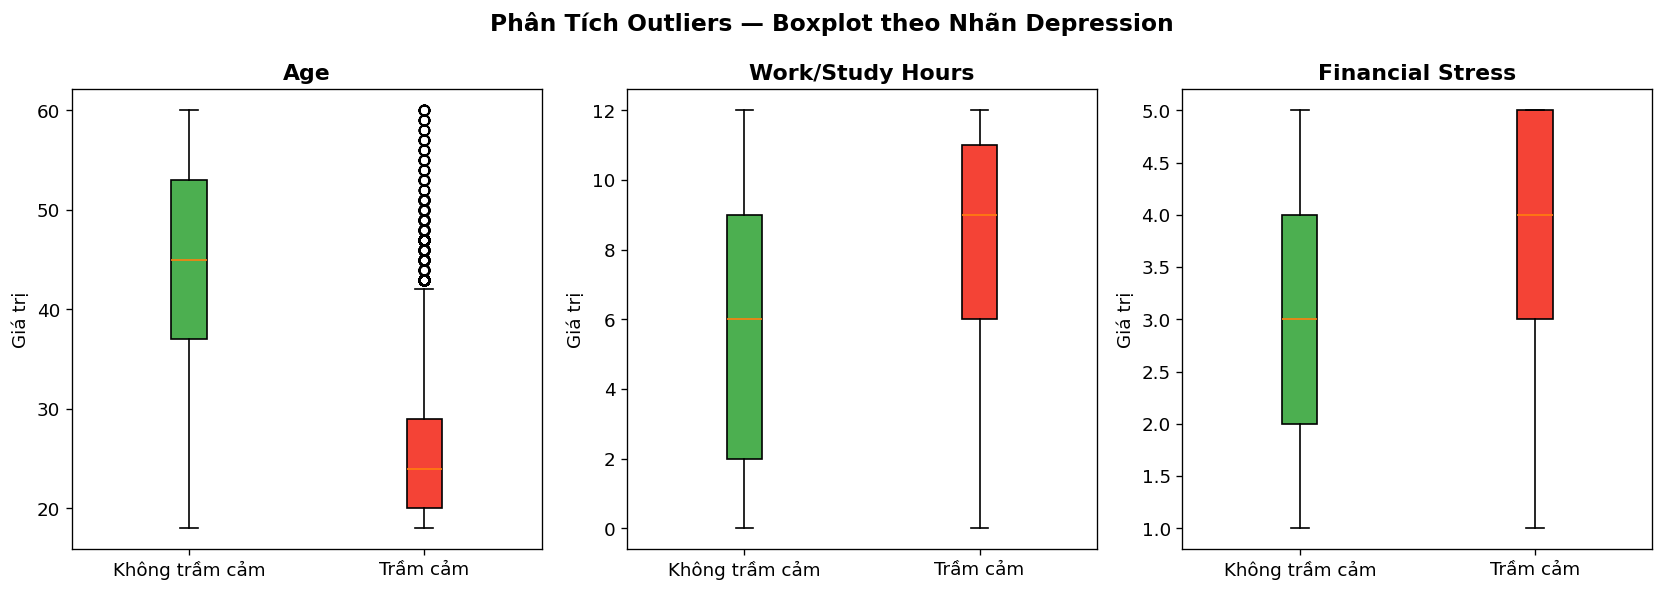


📌 Nhận xét: Hầu hết các biến số không có outliers nghiêm trọng.
   Financial Stress và Work/Study Hours có phân phối khác biệt
   giữa nhóm trầm cảm và không trầm cảm — gợi ý đây là features quan trọng.


In [10]:

# 8. PHÂN TÍCH OUTLIERS

num_check = ['Age', 'Work/Study Hours', 'Financial Stress']

# Phát hiện outliers bằng IQR
print("Phát hiện Outliers bằng phương pháp IQR:")
for col in num_check:
    data = train[col].dropna()
    Q1, Q3 = data.quantile(0.25), data.quantile(0.75)
    IQR    = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out  = ((data < lower) | (data > upper)).sum()
    print(f"  {col}: Q1={Q1:.1f}, Q3={Q3:.1f}, IQR={IQR:.1f} | Outliers: {n_out} ({n_out/len(data)*100:.2f}%)")

# Boxplot theo Depression
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('Phân Tích Outliers — Boxplot theo Nhãn Depression', fontsize=14, fontweight='bold')

for i, col in enumerate(num_check):
    data_0 = train[train['Depression']==0][col].dropna()
    data_1 = train[train['Depression']==1][col].dropna()
    bp = axes[i].boxplot([data_0, data_1], patch_artist=True,
                          labels=['Không trầm cảm', 'Trầm cảm'])
    bp['boxes'][0].set_facecolor('#4CAF50')
    bp['boxes'][1].set_facecolor('#F44336')
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_ylabel('Giá trị')

plt.tight_layout()
plt.show()

print()
print("📌 Nhận xét: Hầu hết các biến số không có outliers nghiêm trọng.")
print("   Financial Stress và Work/Study Hours có phân phối khác biệt")
print("   giữa nhóm trầm cảm và không trầm cảm — gợi ý đây là features quan trọng.")


## Tổng Kết EDA

| Hạng mục | Kết quả |
|---|---|
| Kích thước train | 140,700 dòng × 20 cột |
| Kích thước test | 93,800 dòng × 19 cột |
| Biến mục tiêu | Depression (0: Không, 1: Có) |
| Class imbalance | 81.8% vs 18.2% (tỉ lệ 4.5:1) |
| Cột có missing nhiều | Academic Pressure, CGPA, Study Satisfaction (~80%) |
| Cột có missing ít | Dietary Habits, Financial Stress, Degree (<5 dòng) |
| Biến số | Age, Work/Study Hours, Financial Stress, Work Pressure, CGPA, Academic Pressure, Job/Study Satisfaction |
| Biến phân loại | Gender, City, Profession, Sleep Duration, Dietary Habits, Degree, Suicidal thoughts, Family History |

### Các vấn đề cần xử lý ở bước tiếp theo:
1. **Missing values**: Xử lý riêng cho nhóm Student và Working Professional
2. **Class imbalance**: Cần áp dụng SMOTE hoặc class_weight để cân bằng
3. **Categorical encoding**: Sleep Duration, Dietary Habits, Degree cần chuẩn hóa (có nhiều giá trị bất thường)
4. **Feature Engineering**: Tạo thêm feature từ thông tin có sẵn
